# 03 · Modelagem do Klike Score

> **Parte 2 do desafio:** construir um modelo preditivo para o `klike_score`. Quais features e por quê, qual modelo, como avaliar e quais variáveis mais influenciam o score.

A modelagem segue um protocolo definido antes dos experimentos formais (seção 4). O histórico do repositório registra o protocolo antes dos resultados.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

from klike import modeling, viz
from klike.analysis import add_rate_metrics
from klike.config import TARGET
from klike.data import load_clean, load_raw
from klike.formatting import fmt_compact, fmt_number, fmt_pct, fmt_signed, fmt_signed_pct
from klike.modeling import (
    FeatureSpec,
    build_pipeline,
    compare_on_splits,
    evaluate_on_splits,
    outer_splits,
    prepare_features,
    split_development_test,
    tuned,
)

viz.set_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 140)
PLATFORMS = ["Meta", "TikTok", "LinkedIn"]
cleaned = load_clean()

## 1. Dois cenários de previsão

A decisão que guia o case também guia o modelo: separar o que existe antes da veiculação do que só existe depois.

| | Modelo A · pré-publicação | Modelo B · pós-publicação |
| :-- | :-- | :-- |
| **Usa** | Contexto da campanha e atributos do criativo | Tudo do modelo A, mais taxas de performance |
| **Responde** | Quanto do score dá para prever antes de gastar | Quanto o score acompanha a performance realizada |
| **Papel** | Principal: pontua criativos novos e apoia o recommendations engine | Comparativo: não serve para um criativo que ainda não foi veiculado |

Duas ressalvas valem para tudo o que vem a seguir:

- **Reproduzir o Klike Score não é prever vendas.** O alvo é o score da própria Klike, numa base simulada. Um bom modelo aqui mostra que o score é previsível a partir do criativo, não que o criativo garante resultado financeiro.
- **Prever, pesar na previsão e causar são coisas diferentes.** O modelo pode prever bem o score, e uma variável pode pesar muito na previsão, sem que isso prove que mudar essa variável melhora a performance.

## 2. Features declaradas

O modelo A recebe exatamente 13 colunas, todas conhecidas antes da veiculação. Elas ficam declaradas em `src/klike/modeling.py`, e um teste impede que métricas de performance, o próprio score, o identificador ou a data entrem no modelo.

| Grupo | Colunas | Tratamento |
| :-- | :-- | :-- |
| Contexto | plataforma, categoria, objetivo, faixa etária, retargeting | Categorias e sim/não. Retargeting é decisão de mídia: o engine não pode mudá-lo no criativo |
| Criativo | hook, rosto, CTA, legenda, formato, densidade de texto, duração, música/voz | Densidade de texto como categoria, porque o efeito não é monotônico (Parte 1). Legenda sem marcação vira a categoria "desconhecida" |
| Fora do modelo A | identificador, data, métricas de performance, score | O identificador não generaliza; a data serve só para a checagem temporal; a performance só existe depois do gasto |

**Faltantes.** Duração, música/voz e legenda podem faltar, como no histórico. Na legenda, a ausência já é uma categoria própria, "desconhecida". Duração e música/voz são imputadas pela mediana dentro do pipeline, com o que foi aprendido só no treino de cada partição. Indicadores de ausência para essas duas não entram por padrão: só entram se o experimento F1 mostrar que ajudam. A duração em log também é um experimento (F2).

**Uma única preparação para treino e inferência.** A função `prepare_features` converte e valida as 13 colunas, e é a mesma para o histórico e para uma campanha nova. Ela não depende da limpeza da Parte 1, que exige métricas que uma campanha nova ainda não tem. E a limpeza não mexe em nenhuma das 13 colunas: só corrige métricas de performance.

In [2]:
same = prepare_features(load_raw()).equals(prepare_features(cleaned))
print(
    "Features do modelo A idênticas no CSV bruto e na base limpa: "
    + ("sim" if same else "não")
)
display(prepare_features(cleaned).head(3))

Features do modelo A idênticas no CSV bruto e na base limpa: sim


,platform,category,objective,target_audience_age,format,text_density,subtitle_status,is_retargeting,has_hook,has_face,has_cta,video_duration_s,music_voice_ratio
0,Meta,Branding,awareness,18-24,vertical,medium,sim,0,0,1,1,NaN,0.39
1,LinkedIn,App Install,traffic,25-34,horizontal,low,sim,0,1,1,1,NaN,0.07
2,TikTok,SaaS,traffic,25-34,vertical,medium,sim,0,1,1,1,8.0,0.43


Uma campanha nova só precisa dos campos de pré-publicação. Entradas inválidas geram um erro que lista todos os problemas, em vez de uma previsão silenciosamente errada:

In [3]:
new_campaign = {
    "platform": "TikTok",
    "category": "E-commerce",
    "objective": "conversions",
    "target_audience_age": "18-24",
    "is_retargeting": False,
    "format": "vertical",
    "has_hook": True,
    "has_face": False,
    "has_cta": True,
    "text_density": "low",
    "has_subtitle": None,
    "video_duration_s": 15,
}
display(prepare_features(new_campaign))
try:
    prepare_features({**new_campaign, "platform": "Tiktok", "music_voice_ratio": 1.5})
except ValueError as error:
    print(error)

,platform,category,objective,target_audience_age,format,text_density,subtitle_status,is_retargeting,has_hook,has_face,has_cta,video_duration_s,music_voice_ratio
0,TikTok,E-commerce,conversions,18-24,vertical,low,desconhecido,0,1,0,1,15.0,NaN


Entrada inválida: platform: valor desconhecido ['Tiktok'] (aceitos: Meta, TikTok, LinkedIn); music_voice_ratio: esperado um número entre 0 e 1, ou ausente.


**Modelo B.** Acrescenta sete taxas: CTR, engajamento, retenção, conversão por clique, conversões por mil impressões, CPC e ROAS. Volumes, como impressões e gasto, ficam de fora, porque medem verba. O ROAS não se aplica a Branding: ali ele vale 0, e a categoria Branding, que já está no modelo, absorve a diferença de nível. Assim, a relação com o ROAS é aprendida só com as campanhas que medem receita.

## 3. Experimentos exploratórios, antes do protocolo

> **Leia como exploração, não como desempenho.** Estes experimentos foram feitos para planejar a modelagem, antes de existir a divisão entre desenvolvimento e teste. Usaram as 500 campanhas, inclusive as que depois foram para o teste. O código abaixo é o do diagnóstico original, mantido como foi rodado.

A pergunta era: quanto do score cada grupo de informação explica, e um modelo não linear ganha de um linear?

In [4]:
explore = add_rate_metrics(cleaned)
score = explore[TARGET]
CONTEXT = ["platform", "category", "objective", "target_audience_age"]
CREATIVE_CAT = ["format", "text_density", "subtitle"]
CREATIVE_BIN = ["has_hook", "has_face", "has_cta", "is_retargeting"]
POST = ["ctr", "engagement_rate", "completion_rate", "conversion_rate",
        "conversions_per_mille", "cpc", "roas"]

X_explore = explore.copy()
X_explore["subtitle"] = (
    X_explore["has_subtitle"].map({True: "sim", False: "não"}).fillna("desconhecido")
)
for col in CONTEXT + ["format", "text_density"]:
    X_explore[col] = X_explore[col].astype(str)
for col in CREATIVE_BIN:
    X_explore[col] = X_explore[col].astype(int)
X_explore["log_duration"] = np.log(X_explore["video_duration_s"])


def exploratory_linear(cats, nums):
    columns = ColumnTransformer([
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cats),
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                              StandardScaler()), nums),
    ])
    return make_pipeline(columns, LinearRegression())


def exploratory_boosting(cats, nums):
    columns = ColumnTransformer([("cat", OrdinalEncoder(), cats), ("num", "passthrough", nums)])
    boosting = HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=8, min_samples_leaf=20,
        categorical_features=list(range(len(cats))), random_state=0,
    )
    return make_pipeline(columns, boosting)


PRE_NUM = CREATIVE_BIN + ["log_duration", "music_voice_ratio"]
CREATIVE_NUM = ["has_hook", "has_face", "has_cta", "log_duration", "music_voice_ratio"]
TREE_NUM = CREATIVE_BIN + ["video_duration_s", "music_voice_ratio"]
explorations = {
    "Média (baseline)": (make_pipeline(DummyRegressor()), ["platform"]),
    "Só contexto, linear": (exploratory_linear(CONTEXT, ["is_retargeting"]),
                            CONTEXT + ["is_retargeting"]),
    "Só criativo, linear": (exploratory_linear(CREATIVE_CAT, CREATIVE_NUM),
                            CREATIVE_CAT + CREATIVE_NUM),
    "Pré-publicação, linear": (exploratory_linear(CONTEXT + CREATIVE_CAT, PRE_NUM),
                               CONTEXT + CREATIVE_CAT + PRE_NUM),
    "Pré-publicação, boosting": (exploratory_boosting(CONTEXT + CREATIVE_CAT, TREE_NUM),
                                 CONTEXT + CREATIVE_CAT + TREE_NUM),
    "Pré + pós-publicação, linear": (exploratory_linear(CONTEXT + CREATIVE_CAT, PRE_NUM + POST),
                                     CONTEXT + CREATIVE_CAT + PRE_NUM + POST),
    "Só pós-publicação, linear": (exploratory_linear([], POST), POST),
}
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=0)
exploration = {}
for name, (model, cols) in explorations.items():
    result = cross_validate(
        model, X_explore[cols], score, cv=cv,
        scoring=("neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"),
    )
    exploration[name] = {
        "MAE": fmt_number(-result["test_neg_mean_absolute_error"].mean(), 1),
        "RMSE": fmt_number(-result["test_neg_root_mean_squared_error"].mean(), 1),
        "R²": fmt_number(result["test_r2"].mean(), 2),
        "R², desvio entre partições": fmt_number(result["test_r2"].std(), 2),
    }
display(pd.DataFrame(exploration).T.rename_axis("exploração nas 500 campanhas"))

before_q4 = explore["date"].dt.quarter < 4
temporal = exploratory_linear(CONTEXT + CREATIVE_CAT, PRE_NUM).fit(
    X_explore.loc[before_q4, CONTEXT + CREATIVE_CAT + PRE_NUM], score[before_q4]
)
residual = score[~before_q4] - temporal.predict(
    X_explore.loc[~before_q4, CONTEXT + CREATIVE_CAT + PRE_NUM]
)
r2_q4 = 1 - (residual**2).sum() / ((score[~before_q4] - score[~before_q4].mean()) ** 2).sum()
print(
    f"Treino nos trimestres 1 a 3, avaliação no 4º ({(~before_q4).sum()} campanhas): "
    f"MAE {fmt_number(residual.abs().mean(), 1)} | R² {fmt_number(r2_q4, 2)}"
)

,MAE,RMSE,R²,"R², desvio entre partições"
exploração nas 500 campanhas,,,,
Média (baseline),"12,6","15,6","-0,02","0,02"
"Só contexto, linear","12,7","15,6","-0,02","0,05"
"Só criativo, linear","7,2","9,0","0,66","0,06"
"Pré-publicação, linear","6,9","8,7","0,68","0,06"
"Pré-publicação, boosting","7,4","9,3","0,63","0,07"
"Pré + pós-publicação, linear","5,5","7,0","0,79","0,03"
"Só pós-publicação, linear","9,6","12,0","0,39","0,08"


Treino nos trimestres 1 a 3, avaliação no 4º (136 campanhas): MAE 6,9 | R² 0,72


O que a exploração ensinou, e o que decidimos com ela:

| Aprendizado | Decisão |
| :-- | :-- |
| Só o contexto não prevê o score. Criativo e contexto juntos explicam cerca de dois terços da variação (R² de 0,68) | O modelo A, de pré-publicação, é o principal |
| O modelo linear superou o boosting nesta exploração (R² de 0,68 contra 0,63), coerente com os efeitos aditivos da Parte 1 | A Ridge entra como candidata principal, não como vencedora: a comparação formal, com ajuste justo dos dois, decide |
| As métricas de performance acrescentam explicação (R² de 0,79), mas só existem depois do gasto | Elas ficam no modelo B, comparativo |
| Treinar nos três primeiros trimestres e avaliar no quarto não piorou o resultado (R² de 0,72) | A checagem temporal entra no protocolo como robustez |

Uma consequência importante: a EDA e esta exploração viram as 500 campanhas, inclusive as que depois foram para o teste. Por isso, o teste não é totalmente intocado em relação às escolhas do plano. O protocolo limita esse efeito, com poucas hipóteses definidas antes e o teste consultado uma única vez, mas não o elimina.

## 4. Protocolo

Definido antes dos experimentos formais.

### Divisão e validação

- **Desenvolvimento e teste.** 400 campanhas para desenvolvimento e 100 para o teste final, sorteadas com estratificação por plataforma. O teste só é consultado uma vez, depois que modelo, features e hiperparâmetros estiverem decididos.
- **Validação cruzada aninhada no desenvolvimento.** As mesmas 25 partições externas (5 partes × 5 repetições, estratificadas por plataforma) valem para todos os candidatos. Os hiperparâmetros são escolhidos dentro do treino de cada partição externa, com 3 partes internas e pelo MAE. Assim, o ajuste nunca vê a parte que avalia o candidato.
- **Variabilidade.** Cada métrica vem com média e desvio entre as 25 partições. As partições repetidas compartilham campanhas: a variação mostra estabilidade, mas elas não são amostras independentes, e por isso nenhum teste estatístico formal é feito sobre elas.
- **Checagem temporal, complementar.** Dentro do desenvolvimento, treinar nos três primeiros trimestres e avaliar no quarto. Ela investiga se o desempenho se mantém no tempo, mas um ano de dados simulados não prova estabilidade.

### Candidatos e hiperparâmetros

| Candidato | Papel | Hiperparâmetros testados | Por quê |
| :-- | :-- | :-- | :-- |
| Dummy | Piso: prevê a média do treino | Nenhum | Todo modelo precisa superar este piso |
| Ridge | Linear e interpretável | Penalização (alpha) de 0,01 a 100, em 5 valores | Vai de quase nenhuma penalização a uma penalização forte |
| HistGradientBoosting | Não linear | Taxa de aprendizado 0,05 ou 0,1; 4 ou 8 folhas; mínimo de 10 ou 30 campanhas por folha; 200 iterações | Árvores rasas, com folhas que juntam campanhas suficientes, porque cada treino tem 320 campanhas |

O HistGradientBoosting usa o suporte nativo a categorias, com os códigos fixos da lista de categorias do projeto. Treino e inferência codificam do mesmo jeito, e um teste garante isso. O número de iterações é fixo, sem early stopping: ele reservaria parte de um treino que já é pequeno para a validação interna, e a semente fixa já garante a reprodução dos resultados. Os valores abaixo vêm direto do código:

In [5]:
print(f"Divisão: {1 - modeling.TEST_SIZE:.0%} desenvolvimento, {modeling.TEST_SIZE:.0%} teste")
print(f"Partições externas: {modeling.N_SPLITS} partes × {modeling.N_REPEATS} repetições")
print(f"Partes internas para o ajuste de hiperparâmetros: {modeling.INNER_FOLDS}")
for model, grid in modeling.PARAM_GRIDS.items():
    print(f"{model}: {grid}")
print(f"hgb, fixos: {modeling.HGB_FIXED}")
print(
    "Interação plataforma × formato: combinações com pelo menos "
    f"{modeling.MIN_INTERACTION_SUPPORT} campanhas no treino de cada partição"
)

Divisão: 80% desenvolvimento, 20% teste
Partições externas: 5 partes × 5 repetições
Partes internas para o ajuste de hiperparâmetros: 3
ridge: {'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}
hgb: {'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [4, 8], 'model__min_samples_leaf': [10, 30]}
hgb, fixos: {'max_iter': 200, 'early_stopping': False}
Interação plataforma × formato: combinações com pelo menos 10 campanhas no treino de cada partição


### Experimentos formais

| ID | Hipótese | Comparação | Quando roda |
| :-- | :-- | :-- | :-- |
| M1 | Os efeitos são aditivos, então um modelo linear basta | Dummy, Ridge e HistGradientBoosting | Sempre, primeiro |
| F1 | A ausência seria informativa: se faltar um valor dissesse algo sobre o score, o indicador ajudaria. A Parte 1 indica que não | Com e sem indicadores de ausência para duração e música/voz | Para o vencedor de M1 |
| F2 | Se a duração tiver efeito, ele diminui conforme o vídeo fica mais longo | Duração original contra duração em log | Só se o vencedor for linear: árvores não mudam com transformações que preservam a ordem |
| F3 | O efeito do formato depende da plataforma | Com e sem a interação: colunas por combinação no linear, uma categoria combinada nas árvores. Só combinações com pelo menos 10 campanhas no treino de cada partição viram coluna no linear; TikTok horizontal, sem nenhuma campanha, nunca ganha efeito próprio, e nas árvores uma combinação ausente do treino é tratada como valor ausente | Para o vencedor de M1 |

A pertinência de cada experimento é revista conforme o vencedor de M1, e todo experimento rodado ou descartado vem com a justificativa. Resultados negativos também ficam registrados.

### Como decidir

A métrica principal é o MAE, em pontos de score; RMSE, R² e Spearman são complementares. As referências abaixo orientam a decisão, mas não são regras automáticas:

- **Relevância.** Uma alternativa mais complexa precisa melhorar o MAE de forma que importe. Como referência, cerca de 0,5 ponto, perto de 7% do erro esperado. A decisão olha também a melhora relativa e a variabilidade.
- **Estabilidade.** A melhora deve aparecer na grande maioria das 25 partições, com 80% como referência. Isso indica consistência, não significância estatística, porque as partições não são independentes.
- **Custo.** Complexidade e perda de interpretabilidade contam contra. Na dúvida, fica a alternativa mais simples.

### Avaliação final e diagnósticos

- **Certificação única no teste.** MAE, RMSE, R² e Spearman do modelo escolhido, treinado nas 400 campanhas, com intervalo de bootstrap e comparados ao baseline.
- **Erros por segmento.** Por plataforma e categoria, sempre com o tamanho de cada grupo, nas previsões fora da amostra do desenvolvimento.
- **Calibração e extremos.** Erro médio por faixa de score previsto, que deve ficar perto de zero. Nos extremos do score real, o erro é analisado à parte, explicando a regressão à média: todo modelo de regressão puxa as previsões para o centro, então superestima os scores muito baixos e subestima os muito altos.
- **Ordenação de criativos.** Em que porcentagem dos pares o modelo aponta o criativo de maior score. A análise olha pares da mesma plataforma e separa os pares pela diferença real de score: pares quase empatados não informam uma decisão de marketing. A leitura de negócio usa diferenças de pelo menos 10 pontos, e a tabela mostra também as outras faixas.
- **Interpretação.** Coeficientes em pontos e importância por permutação nas variáveis originais, separando alavancas do criativo de contexto, comparadas com a Parte 1 e com a ressalva de correlação entre variáveis.
- **Modelo B.** O mesmo protocolo, certificado depois do modelo A.

### Depois da certificação

O modelo é reajustado nas 500 campanhas para uso no recommendations engine. As métricas reportadas são as da certificação, do modelo treinado nas 400 campanhas; a versão reajustada não tem métrica própria. O arquivo do modelo não vai para o repositório: o código treina e salva de novo, com os metadados. O modelo salvo leva junto o suporte histórico das combinações de atributos, para o engine sinalizar incerteza e evitar extrapolações em grupos pequenos. A previsão terá uma interface única, que valida, prepara e prevê numa só chamada, sem permitir que alguma etapa seja esquecida.

### Limitações registradas antes dos resultados

- A EDA e a exploração da seção 3 viram as 500 campanhas, inclusive as do teste.
- Não há identificador de criativo. Nenhuma campanha repete todas as variáveis de pré-publicação de outra, o que é um bom sinal, mas não prova que versões do mesmo anúncio não estejam em lados diferentes da divisão.
- A base é simulada, e o alvo é o score da Klike, não um resultado de negócio.

## 5. Divisão e baseline

In [6]:
development, test = split_development_test(cleaned)
sizes = {
    "base inteira": cleaned["platform"].value_counts(),
    "desenvolvimento": development["platform"].value_counts(),
    "teste": test["platform"].value_counts(),
}
display(
    pd.DataFrame(
        {
            name: [f"{counts[p]} ({fmt_pct(counts[p] / counts.sum())})" for p in PLATFORMS]
            for name, counts in sizes.items()
        },
        index=PLATFORMS,
    ).rename_axis("campanhas por plataforma")
)

splits = outer_splits(development)
print(
    f"{len(splits)} partições externas, cada uma com {len(splits[0][0])} campanhas de treino "
    f"e {len(splits[0][1])} de validação"
)

,base inteira,desenvolvimento,teste
campanhas por plataforma,,,
Meta,"241 (48,2%)","193 (48,2%)",48 (48%)
TikTok,"176 (35,2%)","141 (35,2%)",35 (35%)
LinkedIn,"83 (16,6%)","66 (16,5%)",17 (17%)


25 partições externas, cada uma com 320 campanhas de treino e 80 de validação


In [7]:
X_development, y_development = prepare_features(development), development[TARGET]
baseline = evaluate_on_splits(build_pipeline("dummy"), X_development, y_development, splits)
display(
    pd.DataFrame(
        {
            "média": baseline[["mae", "rmse", "r2"]].mean(),
            "desvio entre partições": baseline[["mae", "rmse", "r2"]].std(),
            "menor": baseline[["mae", "rmse", "r2"]].min(),
            "maior": baseline[["mae", "rmse", "r2"]].max(),
        }
    )
    .rename(index={"mae": "MAE", "rmse": "RMSE", "r2": "R²"})
    .map(lambda v: fmt_number(round(v, 2) + 0.0, 2))  # + 0.0 evita "-0,00"
    .rename_axis("baseline: média do treino")
)

,média,desvio entre partições,menor,maior
baseline: média do treino,,,,
MAE,"12,82","0,89","10,91","14,57"
RMSE,"15,87","0,96","14,03","17,76"
R²,"-0,01","0,02","-0,08","0,00"


**O piso.** Prevendo sempre a média do treino, o erro médio é de 12,8 pontos, numa escala de 0 a 100, e varia de 10,9 a 14,6 entre as partições. O R² fica perto de zero, como esperado para quem não usa nenhuma informação. Todo candidato da Etapa 2 é comparado a este piso, nas mesmas 25 partições.

O conjunto de teste está separado e não foi usado: nenhuma métrica dele aparece até a certificação.

## 6. Experimentos formais

Todos rodam no desenvolvimento, nas mesmas 25 partições, com os hiperparâmetros ajustados dentro do treino de cada partição. O teste continua intocado.

### 6.1 M1 · Algoritmos

**Hipótese.** A Parte 1 mostrou efeitos aditivos e nenhuma diferença robusta de efeito entre plataformas ou públicos. Se for assim, um modelo linear basta, e um modelo não linear não deveria ganhar dele.

**Comparação.** Dummy, Ridge e HistGradientBoosting, com o conjunto base de features, cada um com o seu espaço de hiperparâmetros (seção 4).

In [8]:
m1 = {
    "Dummy": evaluate_on_splits(build_pipeline("dummy"), X_development, y_development, splits),
    "Ridge": evaluate_on_splits(tuned("ridge"), X_development, y_development, splits),
    "HistGradientBoosting": evaluate_on_splits(
        tuned("hgb"), X_development, y_development, splits
    ),
}
METRIC_LABELS = {"mae": "MAE", "rmse": "RMSE", "r2": "R²", "spearman": "Spearman"}


def mean_and_spread(folds: pd.DataFrame, metric: str) -> str:
    """Média e desvio entre partições, no formato '7,01 ± 0,50'."""
    values = folds[metric]
    if values.isna().all():
        return "não se aplica"
    return f"{fmt_number(values.mean(), 2)} ± {fmt_number(values.std(), 2)}"


def paired(candidate: pd.DataFrame, reference: pd.DataFrame) -> dict:
    """Comparação pareada, nas mesmas partições, pelo MAE e pelo RMSE."""
    mae = compare_on_splits(candidate, reference)
    rmse = compare_on_splits(candidate, reference, metric="rmse")
    return {
        "redução do MAE (pontos)": fmt_signed(mae["melhora"], 2),
        "redução relativa": fmt_signed_pct(mae["melhora_relativa"], 1),
        "desvio da diferença": fmt_number(mae["desvio"], 2),
        "partições melhores (MAE)": fmt_pct(mae["vitorias"]),
        "partições melhores (RMSE)": fmt_pct(rmse["vitorias"]),
    }


display(
    pd.DataFrame(
        {
            name: {label: mean_and_spread(folds, metric) for metric, label in METRIC_LABELS.items()}
            for name, folds in m1.items()
        }
    ).T.rename_axis("média ± desvio entre as 25 partições")
)
display(
    pd.DataFrame(
        {
            "Ridge sobre o Dummy": paired(m1["Ridge"], m1["Dummy"]),
            "HistGradientBoosting sobre o Dummy": paired(m1["HistGradientBoosting"], m1["Dummy"]),
            "HistGradientBoosting sobre a Ridge": paired(m1["HistGradientBoosting"], m1["Ridge"]),
        }
    ).T.rename_axis("comparação pareada")
)
alphas = Counter(params["model__alpha"] for params in m1["Ridge"]["hiperparametros"])
leaves = Counter(
    params["model__max_leaf_nodes"] for params in m1["HistGradientBoosting"]["hiperparametros"]
)


def partitions(n: int) -> str:
    return f"{n} {'partição' if n == 1 else 'partições'}"


print(
    "Ridge, penalização escolhida: "
    + ", ".join(f"alpha {fmt_compact(a)} em {partitions(n)}" for a, n in alphas.most_common())
)
print(
    "HistGradientBoosting, tamanho das árvores escolhido: "
    + ", ".join(f"{size} folhas em {partitions(n)}" for size, n in leaves.most_common())
)

,MAE,RMSE,R²,Spearman
média ± desvio entre as 25 partições,,,,
Dummy,"12,82 ± 0,89","15,87 ± 0,96","-0,01 ± 0,02",não se aplica
Ridge,"7,01 ± 0,50","8,76 ± 0,71","0,69 ± 0,04","0,82 ± 0,02"
HistGradientBoosting,"7,24 ± 0,60","9,15 ± 0,78","0,66 ± 0,05","0,79 ± 0,03"


,redução do MAE (pontos),redução relativa,desvio da diferença,partições melhores (MAE),partições melhores (RMSE)
comparação pareada,,,,,
Ridge sobre o Dummy,"+5,82","+45,3%","0,73",100%,100%
HistGradientBoosting sobre o Dummy,"+5,58","+43,5%","0,68",100%,100%
HistGradientBoosting sobre a Ridge,"−0,23","−3,3%","0,37",32%,12%


Ridge, penalização escolhida: alpha 1 em 23 partições, alpha 0,01 em 1 partição, alpha 0,1 em 1 partição
HistGradientBoosting, tamanho das árvores escolhido: 4 folhas em 21 partições, 8 folhas em 4 partições


**O que aprendemos.** A Ridge erra, em média, 7,0 pontos numa escala de 0 a 100, contra 12,8 do piso: 45% menos erro, com melhora em todas as 25 partições. O HistGradientBoosting também supera o piso, mas erra em média 0,23 ponto a mais que a Ridge e só a supera em 32% das partições, ou 12% pelo RMSE. Ou seja, entre os candidatos e hiperparâmetros investigados, o HistGradientBoosting não mostrou vantagem sobre a Ridge. O ajuste interno preferiu as árvores mais simples do espaço testado, com 4 folhas, em 21 das 25 partições. Isso é compatível com essa conclusão, mas não prova que não existam relações não lineares: outros modelos, outros hiperparâmetros ou mais dados poderiam encontrá-las. A penalização da Ridge foi a mesma em 23 das 25 partições, então o ajuste dela é estável.

**Decisão: Ridge.** Erra menos, varia menos entre partições e é interpretável: cada coeficiente vira pontos de score, o que a Parte 3 vai usar. Como a vencedora é linear, os três experimentos de features são pertinentes.

### 6.2 F1 a F3 · Features, na Ridge

Cada experimento compara a Ridge base com a Ridge mais uma alteração, nas mesmas partições e com o mesmo ajuste interno.

| ID | Hipótese | Alteração testada |
| :-- | :-- | :-- |
| F1 | Se faltar um valor dissesse algo sobre o score, um indicador de ausência ajudaria. A Parte 1 indicou ausência compatível com acaso | Indicadores para duração e música/voz |
| F2 | Se a duração tiver efeito, ele diminui conforme o vídeo fica mais longo | Duração em log |
| F3 | O efeito do formato depende da plataforma, como sugeriu a Parte 1 | Interação plataforma × formato, nas combinações com suporte no treino |

In [9]:
base = m1["Ridge"]
feature_experiments = {
    "F1 · indicadores de ausência": FeatureSpec(missing_indicators=True),
    "F2 · duração em log": FeatureSpec(log_duration=True),
    "F3 · plataforma × formato": FeatureSpec(platform_format=True),
}
f_results = {
    name: evaluate_on_splits(tuned("ridge", spec), X_development, y_development, splits)
    for name, spec in feature_experiments.items()
}
display(
    pd.DataFrame(
        {
            name: {"MAE": mean_and_spread(folds, "mae"), **paired(folds, base)}
            for name, folds in f_results.items()
        }
    ).T.rename_axis("contra a Ridge base")
)


def interactions_in(train: np.ndarray) -> tuple[str, ...]:
    """Combinações de plataforma e formato com suporte no treino de uma partição."""
    pipeline = build_pipeline("ridge", FeatureSpec(platform_format=True))
    names = pipeline.fit(X_development.iloc[train], y_development.iloc[train])[0]
    return tuple(name for name in names.get_feature_names_out() if "×" in name)


for combinations, n in Counter(interactions_in(train) for train, _ in splits).items():
    print(f"F3, interações criadas em {n} das {len(splits)} partições: {', '.join(combinations)}")

,MAE,redução do MAE (pontos),redução relativa,desvio da diferença,partições melhores (MAE),partições melhores (RMSE)
contra a Ridge base,,,,,,
F1 · indicadores de ausência,"7,04 ± 0,51","−0,03","−0,4%","0,05",40%,36%
F2 · duração em log,"7,01 ± 0,51",0,0%,"0,04",56%,52%
F3 · plataforma × formato,"6,78 ± 0,48","+0,23","+3,3%","0,18",92%,96%


F3, interações criadas em 25 das 25 partições: TikTok × quadrado, LinkedIn × quadrado, LinkedIn × horizontal


**O que aprendemos, experimento por experimento:**

- **F1, indicadores de ausência: fica de fora.** O MAE piora 0,03 ponto, e a variante só é melhor em 40% das partições: os indicadores não trouxeram ganho preditivo consistente, o que justifica deixá-los de fora. O resultado é compatível com a Parte 1, que não encontrou relação entre a ausência e as variáveis observadas, mas não prova que a ausência seja completamente aleatória.
- **F2, duração em log: fica de fora.** O MAE não muda, e cada versão vence em cerca de metade das partições. Também é coerente com a Parte 1, onde a duração não mostrou efeito. No empate, fica a forma mais simples, a duração original.
- **F3, plataforma × formato: entra.** O MAE cai 0,23 ponto, ou 3,3%, com melhora em 92% das partições, e em 96% pelo RMSE. A melhora fica abaixo da referência de 0,5 ponto do protocolo, então a decisão pesou os outros critérios: ela é muito estável, custa só três termos, mantém o modelo linear e interpretável e deixa o efeito do formato específico de cada plataforma. Isso importa para o produto: sem a interação, o modelo aplicaria o mesmo efeito de formato a todas as plataformas, embora a Parte 1 tenha mostrado o vídeo horizontal com score menor na Meta e como o formato mais usado no LinkedIn. TikTok horizontal, que não aparece na base, nunca ganhou efeito próprio.

Como só uma alteração entrou, não há combinação de alterações a conferir.

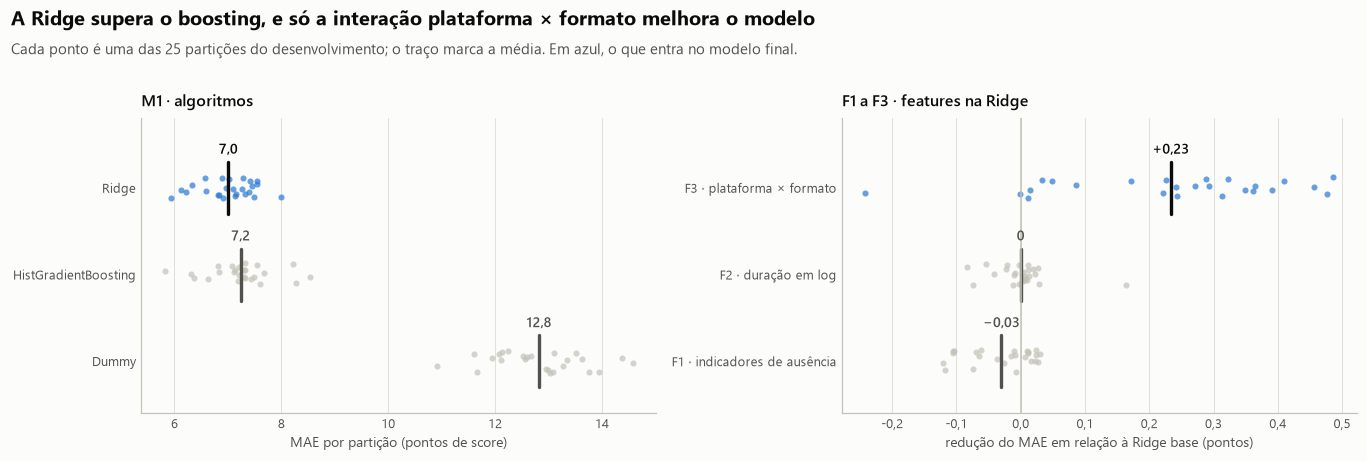

In [10]:
rng = np.random.default_rng(0)  # só para espalhar os pontos na vertical


def strip(ax, rows, highlight):
    """Uma linha por candidato: os valores das partições como pontos e a média como traço."""
    for y, (label, values, show) in enumerate(rows):
        chosen = label == highlight
        ink = viz.INK if chosen else viz.INK_SECONDARY
        ax.scatter(values, y + rng.uniform(-0.13, 0.13, len(values)), s=16, linewidth=0,
                   color=viz.ACCENT if chosen else viz.CONTEXT, alpha=0.7)
        mean = np.mean(values)
        ax.plot([mean, mean], [y - 0.3, y + 0.3], linewidth=2.2, color=ink)
        ax.text(mean, y + 0.36, show(mean), ha="center", va="bottom", fontsize=9, color=ink,
                fontweight="semibold")
    ax.set_yticks(range(len(rows)), [label for label, _, _ in rows])
    ax.set_ylim(-0.6, len(rows) - 0.2)
    ax.grid(axis="y", visible=False)


fig, (left, right) = plt.subplots(1, 2, figsize=(12.5, 4.3))
strip(
    left,
    [(name, m1[name]["mae"].to_numpy(), lambda v: fmt_number(v, 1))
     for name in ["Dummy", "HistGradientBoosting", "Ridge"]],
    highlight="Ridge",
)
left.xaxis.set_major_formatter(viz.decimal_formatter(0))
left.set_xlabel("MAE por partição (pontos de score)")
left.set_title("M1 · algoritmos")
strip(
    right,
    [(name, base["mae"].to_numpy() - folds["mae"].to_numpy(), lambda v: fmt_signed(v, 2))
     for name, folds in f_results.items()],
    highlight="F3 · plataforma × formato",
)
right.axvline(0, color=viz.BASELINE, linewidth=1)
right.xaxis.set_major_formatter(viz.decimal_formatter(1))
right.set_xlabel("redução do MAE em relação à Ridge base (pontos)")
right.set_title("F1 a F3 · features na Ridge")
viz.add_header(
    fig,
    "A Ridge supera o boosting, e só a interação plataforma × formato melhora o modelo",
    "Cada ponto é uma das 25 partições do desenvolvimento; o traço marca a média. "
    "Em azul, o que entra no modelo final.",
)
viz.save(fig, "03_selecao_modelo")
plt.show()

### 6.3 Especificação congelada

| Item | Escolha |
| :-- | :-- |
| Algoritmo | Ridge, com a penalização escolhida por validação cruzada interna |
| Features | As 13 de pré-publicação: categorias contra a referência, binárias em 0 ou 1, duração e música/voz imputadas pela mediana do treino e padronizadas |
| Alteração adotada | Interação plataforma × formato, nas combinações com pelo menos 10 campanhas no treino (F3) |
| Alterações descartadas | Indicadores de ausência (F1) e duração em log (F2) |

A especificação fica registrada no código e é a que vai para a certificação no teste. Até aqui, o teste não foi consultado.

**Uma ressalva sobre o número.** O MAE de 6,78 da especificação escolhida vem das mesmas partições que orientaram a escolha. Por isso, pode trazer algum otimismo de seleção e não substitui a avaliação final nas 100 campanhas reservadas.

In [11]:
print(f"Modelo escolhido: {modeling.SELECTED_MODEL} | features: {modeling.SELECTED_SPEC}")

Modelo escolhido: ridge | features: FeatureSpec(missing_indicators=False, log_duration=False, platform_format=True)
